# Week 11: DBSCAN and Hierarchical Agglomerative Clustering

### Research Question

Can DBSCAN and Hierarchical Agglomerative Clustering identify
meaningful NBA game patterns that K-Means could not capture?

### Objectives

1. Apply DBSCAN and investigate epsilon and MinPts.
2. Identify core, border, and noise points.
3. Compare different hierarchical clustering linkage methods.
4. Create and interpret dendrograms.
5. Evaluate cluster quality using silhouette scores.
6. Compare clustering results with Week 10 K-Means.
7. Investigate whether unusual NBA games have different
   sportsbook prediction errors.
8. Evaluate limitations and derive evidence-supported conclusions.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import (
    DBSCAN,
    AgglomerativeClustering,
    KMeans
)

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score
)

from scipy.cluster.hierarchy import (
    linkage,
    dendrogram
)

In [ ]:
# Load cleaned NBA dataset
df = pd.read_csv(
    "../data/processed/merged_games_betting.csv",
    low_memory=False
)

# Prepare chronological ordering
df["game_date"] = pd.to_datetime(df["gameDate"])

df = (
    df.sort_values("game_date")
    .reset_index(drop=True)
)

# Sportsbook scoring residual
df["score_residual"] = (
    df["actual_total"] - df["total"]
)

# Chronological 80/20 split
split_idx = int(len(df) * 0.80)

cutoff_date = df.loc[
    split_idx, "game_date"
]

train_df = df[
    df["game_date"] < cutoff_date
].copy()

test_df = df[
    df["game_date"] >= cutoff_date
].copy()

# Dataset validation
print("Dataset shape:", df.shape)

print("\nTraining games:", len(train_df))
print("Testing games:", len(test_df))

print("\nTraining period:")
print(
    train_df["game_date"].min(),
    "to",
    train_df["game_date"].max()
)

print("\nTesting period:")
print(
    test_df["game_date"].min(),
    "to",
    test_df["game_date"].max()
)

print("\nRequired columns:")
required_cols = [
    "hometeamId",
    "awayteamId",
    "homeScore",
    "awayScore",
    "total",
    "spread",
    "actual_total"
]

print(df[required_cols].dtypes)

print("\nMissing values:")
print(df[required_cols].isna().sum())

Dataset shape: (21965, 56)

Training games: 17568
Testing games: 4397

Training period:
2007-10-30 00:00:00 to 2022-02-16 00:00:00

Testing period:
2022-02-17 00:00:00 to 2025-06-19 00:00:00

Required columns:
hometeamId        int64
awayteamId        int64
homeScore         int64
awayScore         int64
total           float64
spread          float64
actual_total      int64
dtype: object

Missing values:
hometeamId      0
awayteamId      0
homeScore       0
awayScore       0
total           0
spread          3
actual_total    0
dtype: int64


## Historical NBA Features and Scaling

The same five pregame features from Week 10 are used for
DBSCAN and hierarchical clustering.

These features represent sportsbook expectations, recent
team scoring performance, and rest differences.

Historical features use previous games only. Final game
scores are reserved for analyzing cluster outcomes.

Missing values are imputed and features are standardized
using training data only.

In [2]:
# Recreate historical features from Week 10

games = df.copy()

games["hometeamId"] = games["hometeamId"].astype(str)
games["awayteamId"] = games["awayteamId"].astype(str)

# One observation per team per game
home_games = pd.DataFrame({
    "team": games["hometeamId"],
    "game_date": games["game_date"],
    "points_for": games["homeScore"],
    "points_against": games["awayScore"],
    "residual": games["score_residual"]
})

away_games = pd.DataFrame({
    "team": games["awayteamId"],
    "game_date": games["game_date"],
    "points_for": games["awayScore"],
    "points_against": games["homeScore"],
    "residual": games["score_residual"]
})

team_games = pd.concat(
    [home_games, away_games],
    ignore_index=True
)

# Aggregate games by team and date
daily = (
    team_games
    .groupby(["team", "game_date"], as_index=False)
    .agg({
        "points_for": "mean",
        "points_against": "mean",
        "residual": "mean"
    })
    .sort_values(["team", "game_date"])
    .reset_index(drop=True)
)

# Five-game rolling averages: past games only
for col in ["points_for", "points_against", "residual"]:
    daily[f"{col}_5"] = (
        daily.groupby("team")[col]
        .transform(
            lambda s: s.shift(1)
            .rolling(5, min_periods=3)
            .mean()
        )
    )

# Rest days
previous_date = daily.groupby("team")["game_date"].shift(1)

daily["rest_days"] = (
    (daily["game_date"] - previous_date).dt.days - 1
).clip(lower=0, upper=7)

history_cols = [
    "points_for_5",
    "points_against_5",
    "residual_5",
    "rest_days"
]

# Prepare home and away histories
home_history = daily[
    ["team", "game_date"] + history_cols
].rename(columns={
    "team": "hometeamId",
    **{c: f"home_{c}" for c in history_cols}
})

away_history = daily[
    ["team", "game_date"] + history_cols
].rename(columns={
    "team": "awayteamId",
    **{c: f"away_{c}" for c in history_cols}
})

# Merge historical information
games = games.merge(
    home_history,
    on=["hometeamId", "game_date"],
    how="left",
    validate="many_to_one"
)

games = games.merge(
    away_history,
    on=["awayteamId", "game_date"],
    how="left",
    validate="many_to_one"
)

# Historical scoring estimate
games["expected_total_5"] = (
    games["home_points_for_5"]
    + games["away_points_against_5"]
    + games["away_points_for_5"]
    + games["home_points_against_5"]
) / 2

games["scoring_edge_5"] = (
    games["expected_total_5"] - games["total"]
)

games["recent_residual_5"] = (
    games["home_residual_5"]
    + games["away_residual_5"]
) / 2

games["rest_difference"] = (
    games["home_rest_days"]
    - games["away_rest_days"]
)

# Same five clustering features as Week 10
cluster_features = [
    "total",
    "spread",
    "scoring_edge_5",
    "recent_residual_5",
    "rest_difference"
]

# Preserve the chronological boundary
train_df = games[games["game_date"] < cutoff_date].copy()
test_df = games[games["game_date"] >= cutoff_date].copy()

# Training-only preprocessing
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_imputed = imputer.fit_transform(
    train_df[cluster_features]
)

X_train_scaled = scaler.fit_transform(X_train_imputed)

X_test_scaled = scaler.transform(
    imputer.transform(test_df[cluster_features])
)

print("Training observations:", len(X_train_scaled))
print("Testing observations:", len(X_test_scaled))
print("Number of features:", X_train_scaled.shape[1])

print("\nMissing values before imputation:")
display(train_df[cluster_features].isna().sum())

print("\nStandardized feature summary:")
display(
    pd.DataFrame(
        X_train_scaled,
        columns=cluster_features
    ).describe().loc[["mean", "std"]].round(3)
)

Training observations: 17568
Testing observations: 4397
Number of features: 5

Missing values before imputation:


total                 0
spread                1
scoring_edge_5       54
recent_residual_5    54
rest_difference      20
dtype: int64


Standardized feature summary:


,total,spread,scoring_edge_5,recent_residual_5,rest_difference
mean,0.0,0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0


## DBSCAN: K-Nearest-Neighbor Distance Analysis

DBSCAN is a density-based clustering algorithm that identifies
groups of closely positioned observations and separates noise.

Unlike K-Means, DBSCAN does not require the number of clusters
to be specified beforehand.

A k-distance plot is used to investigate suitable epsilon
values for neighborhood sizes of 10 and 20 observations.

A reproducible sample of 5,000 training games is used
to keep the analysis computationally manageable.

We will examine the distance distribution and look for
a bend where distances begin increasing more sharply.


MinPts = 10
Distance percentiles:
[0.671 0.873 1.087 1.278 1.916]

MinPts = 20
Distance percentiles:
[0.825 1.003 1.239 1.479 2.257]


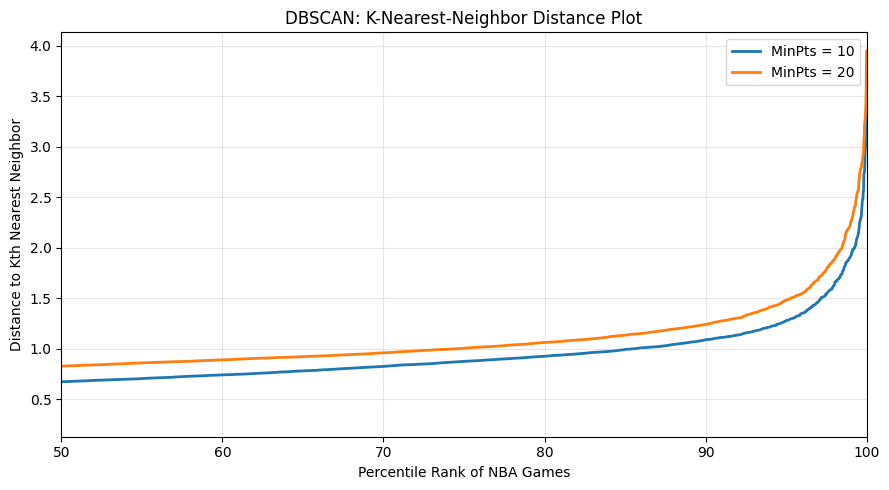

In [3]:
# K-distance analysis for DBSCAN

# Reproducible sample from training games
rng = np.random.default_rng(42)

sample_idx = np.sort(
    rng.choice(
        len(X_train_scaled),
        size=5000,
        replace=False
    )
)

X_dbscan_sample = X_train_scaled[sample_idx]

# Keep corresponding original game information
dbscan_sample_df = train_df.iloc[sample_idx].copy()

# Neighborhood sizes to investigate
min_samples_values = [10, 20]

k_distance_results = {}

fig, ax = plt.subplots(figsize=(9, 5))

for min_samples in min_samples_values:

    neighbors = NearestNeighbors(
        n_neighbors=min_samples,
        metric="euclidean",
        n_jobs=-1
    )

    neighbors.fit(X_dbscan_sample)

    distances, indices = neighbors.kneighbors(
        X_dbscan_sample
    )

    # Distance to the kth nearest observation
    k_distances = np.sort(
        distances[:, -1]
    )

    k_distance_results[min_samples] = k_distances

    # Plot distances by percentile rank
    percentile_rank = np.linspace(
        0, 100, len(k_distances)
    )

    ax.plot(
        percentile_rank,
        k_distances,
        label=f"MinPts = {min_samples}",
        linewidth=2
    )

    print(f"\nMinPts = {min_samples}")

    print("Distance percentiles:")
    print(
        np.round(
            np.percentile(
                k_distances,
                [50, 75, 90, 95, 99]
            ),
            3
        )
    )

ax.set_title(
    "DBSCAN: K-Nearest-Neighbor Distance Plot"
)

ax.set_xlabel("Percentile Rank of NBA Games")
ax.set_ylabel("Distance to Kth Nearest Neighbor")

ax.set_xlim(50, 100)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

## DBSCAN Hyperparameter Sensitivity

The k-distance plot suggests that epsilon values between
approximately 1.1 and 1.7 may be reasonable candidates.

DBSCAN is evaluated using different combinations of
epsilon and MinPts.

The analysis examines the number of clusters, core points,
border points, noise observations, and cluster-size balance.

This helps determine whether the identified groups are
meaningful or highly sensitive to parameter selection.

In [4]:
# DBSCAN hyperparameter comparison

dbscan_results = []
dbscan_models = {}

parameter_combinations = {
    10: [1.1, 1.3, 1.5],
    20: [1.3, 1.5, 1.7]
}

for min_samples, eps_values in parameter_combinations.items():

    for eps in eps_values:

        model = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            metric="euclidean",
            n_jobs=-1
        )

        labels = model.fit_predict(X_dbscan_sample)

        # Identify clusters, excluding noise (-1)
        cluster_labels = labels[labels != -1]

        n_clusters = len(np.unique(cluster_labels))

        # Count types of points
        n_noise = np.sum(labels == -1)
        n_core = len(model.core_sample_indices_)
        n_border = len(labels) - n_noise - n_core

        # Largest cluster as a share of clustered observations
        if len(cluster_labels) > 0:
            cluster_sizes = np.unique(
                cluster_labels,
                return_counts=True
            )[1]

            largest_cluster_pct = (
                cluster_sizes.max() / len(cluster_labels) * 100
            )
        else:
            largest_cluster_pct = np.nan

        dbscan_results.append({
            "Epsilon": eps,
            "MinPts": min_samples,
            "Clusters": n_clusters,
            "Core Points": n_core,
            "Border Points": n_border,
            "Noise Points": n_noise,
            "Noise (%)": n_noise / len(labels) * 100,
            "Largest Cluster (%)": largest_cluster_pct
        })

        dbscan_models[(eps, min_samples)] = model

# Display results
dbscan_results_df = pd.DataFrame(dbscan_results)

display(
    dbscan_results_df.sort_values(
        ["MinPts", "Epsilon"]
    ).round(2)
)

,Epsilon,MinPts,Clusters,Core Points,Border Points,Noise Points,Noise (%),Largest Cluster (%)
0,1.1,10,1,4528,293,179,3.58,100.0
1,1.3,10,1,4772,143,85,1.70,100.0
2,1.5,10,1,4858,85,57,1.14,100.0
3,1.3,20,1,4594,289,117,2.34,100.0
4,1.5,20,1,4765,166,69,1.38,100.0
5,1.7,20,1,4850,97,53,1.06,100.0


## DBSCAN: Core, Border, and Noise Point Analysis

The DBSCAN model using epsilon = 1.1 and MinPts = 10
is selected to investigate the characteristics of different
point types.

Core points belong to dense neighborhoods, border points
are associated with dense regions, and noise points are
not density-reachable from a core point.

We compare their pregame features and sportsbook prediction
errors to determine whether unusual game characteristics
are associated with greater prediction difficulty.

Actual scores are used only for evaluation, not clustering.

In [5]:
# DBSCAN core, border, and noise analysis

# Retrieve the selected DBSCAN model
selected_dbscan = dbscan_models[(1.1, 10)]

labels = selected_dbscan.labels_

# Classify observations by DBSCAN point type
point_types = np.full(
    len(labels),
    "Border",
    dtype=object
)

point_types[labels == -1] = "Noise"
point_types[selected_dbscan.core_sample_indices_] = "Core"

# Match point types to the sampled NBA games
noise_analysis = dbscan_sample_df.copy()

noise_analysis["Point_Type"] = point_types

# Sportsbook prediction error
noise_analysis["Signed_Error"] = (
    noise_analysis["actual_total"]
    - noise_analysis["total"]
)

noise_analysis["Absolute_Error"] = (
    noise_analysis["Signed_Error"].abs()
)

# Measure how unusual the pregame features are
noise_analysis["Abs_Scoring_Edge"] = (
    noise_analysis["scoring_edge_5"].abs()
)

noise_analysis["Abs_Rest_Difference"] = (
    noise_analysis["rest_difference"].abs()
)

# Check whether missing feature values are associated with noise
noise_analysis["Missing_Pregame_Feature"] = (
    noise_analysis[cluster_features].isna().any(axis=1)
)

# Compare point types
point_profile = (
    noise_analysis
    .groupby("Point_Type")
    .agg(
        Games=("actual_total", "size"),
        Avg_Total=("total", "mean"),
        Avg_Spread=("spread", "mean"),
        Avg_Abs_Scoring_Edge=("Abs_Scoring_Edge", "mean"),
        Avg_Abs_Rest_Difference=("Abs_Rest_Difference", "mean"),
        Sportsbook_MAE=("Absolute_Error", "mean"),
        Avg_Signed_Error=("Signed_Error", "mean"),
        Missing_Feature_Rate=("Missing_Pregame_Feature", "mean")
    )
)

point_profile["Share_Pct"] = (
    point_profile["Games"] / len(noise_analysis) * 100
)

point_profile["Missing_Feature_Rate"] *= 100

# Arrange from core to border to noise
point_profile = point_profile.reindex([
    "Core", "Border", "Noise"
])

display(point_profile.round(2))

,Games,Avg_Total,Avg_Spread,Avg_Abs_Scoring_Edge,Avg_Abs_Rest_Difference,Sportsbook_MAE,Avg_Signed_Error,Missing_Feature_Rate,Share_Pct
Point_Type,,,,,,,,,
Core,4528,207.09,5.87,4.89,0.61,14.22,0.19,0.18,90.56
Border,293,209.58,8.27,8.75,1.67,14.71,0.06,0.00,5.86
Noise,179,208.33,7.35,9.78,3.34,13.97,1.80,0.00,3.58


### Interpretation

DBSCAN identified 179 noise observations, representing 3.58% of
the sampled training games.

Noise observations exhibited larger historical scoring edges
and rest differences than core observations, suggesting that
they represent unusual pregame matchup characteristics.

However, sportsbook MAE was 13.97 points for noise observations,
compared with 14.22 for core observations.

This unexpected finding suggests that games with unusual
pregame characteristics are not necessarily more difficult
for sportsbooks to predict.

Because this analysis is exploratory and based on a sample,
the differences should not be interpreted as evidence of
statistically significant differences in prediction accuracy.

## Hierarchical Agglomerative Clustering: Linkage Comparison

Hierarchical Agglomerative Clustering is applied to investigate
whether NBA games form meaningful groups under different
cluster-merging strategies.

Four linkage methods are compared:
- Single linkage
- Complete linkage
- Average linkage
- Ward linkage

Each method is evaluated using two and four clusters, reflecting
the candidate cluster counts investigated in Week 10.

Silhouette scores, cluster sizes, and cluster balance are
examined to identify differences in clustering behavior.

A K-Means benchmark is evaluated on the same sample for
a fairer comparison.

In [6]:
# Compare HAC linkage methods

# Reproducible sample
rng = np.random.default_rng(42)

hac_sample_idx = np.sort(
    rng.choice(
        len(X_train_scaled),
        size=1500,
        replace=False
    )
)

X_hac = X_train_scaled[hac_sample_idx]

hac_sample_df = train_df.iloc[hac_sample_idx].copy()

linkage_methods = ["single", "complete", "average", "ward"]
cluster_counts = [2, 4]

hac_results = []
hac_models = {}
hac_labels = {}

# Evaluate different HAC methods
for method in linkage_methods:

    for k in cluster_counts:

        model = AgglomerativeClustering(
            n_clusters=k,
            linkage=method,
            metric="euclidean"
        )

        labels = model.fit_predict(X_hac)

        hac_models[(method, k)] = model
        hac_labels[(method, k)] = labels

        # Silhouette score
        score = silhouette_score(
            X_hac,
            labels,
            metric="euclidean"
        )

        # Cluster sizes
        sizes = np.bincount(labels)

        hac_results.append({
            "Method": method,
            "K": k,
            "Silhouette": score,
            "Smallest Cluster": sizes.min(),
            "Largest Cluster (%)": (
                sizes.max() / len(labels) * 100
            )
        })

# Compare K-Means on the same sample
for k in cluster_counts:

    kmeans = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels = kmeans.fit_predict(X_hac)

    sizes = np.bincount(labels)

    hac_results.append({
        "Method": "K-Means",
        "K": k,
        "Silhouette": silhouette_score(
            X_hac,
            labels,
            metric="euclidean"
        ),
        "Smallest Cluster": sizes.min(),
        "Largest Cluster (%)": (
            sizes.max() / len(labels) * 100
        )
    })

# Results
hac_results_df = pd.DataFrame(hac_results)

hac_results_df = hac_results_df.sort_values(
    ["K", "Silhouette"],
    ascending=[True, False]
)

display(hac_results_df.round(4))

,Method,K,Silhouette,Smallest Cluster,Largest Cluster (%)
0,single,2,0.5582,1,99.9333
4,average,2,0.4940,1,99.9333
8,K-Means,2,0.1876,748,50.1333
6,ward,2,0.1681,322,78.5333
2,complete,2,0.1248,598,60.1333
1,single,4,0.3855,1,99.8000
5,average,4,0.3001,1,98.0667
9,K-Means,4,0.1804,317,30.2667
7,ward,4,0.1196,322,28.8000
3,complete,4,0.1186,13,52.4000


## Hierarchical Clustering: Dendrogram Analysis

Dendrograms are created using Ward and single linkage
to visualize how NBA games are merged into clusters.

Ward linkage minimizes the increase in within-cluster
variance, while single linkage merges clusters based
on the closest pair of observations.

The dendrograms are truncated to the final 25 branches
for readability. Earlier merges are represented by
aggregated branches.

The objective is to understand why linkage methods
produce different clustering structures and cluster sizes.

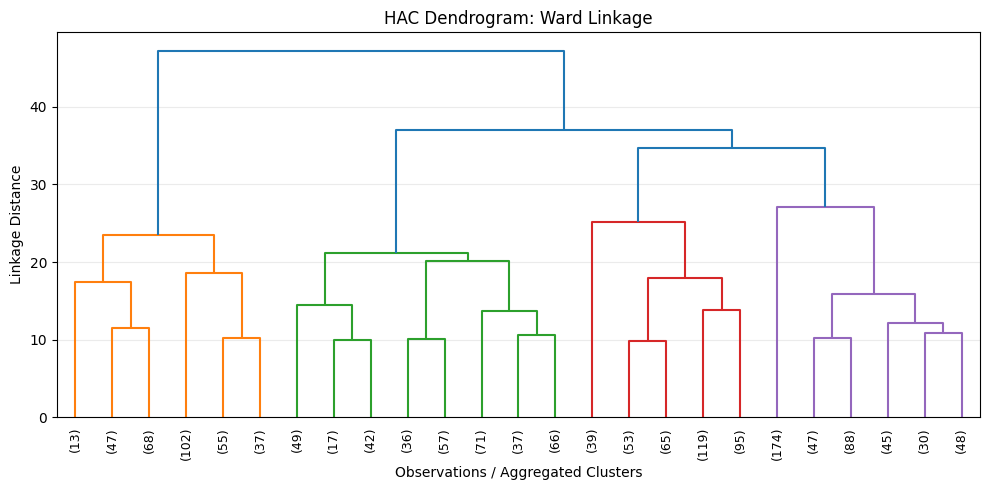

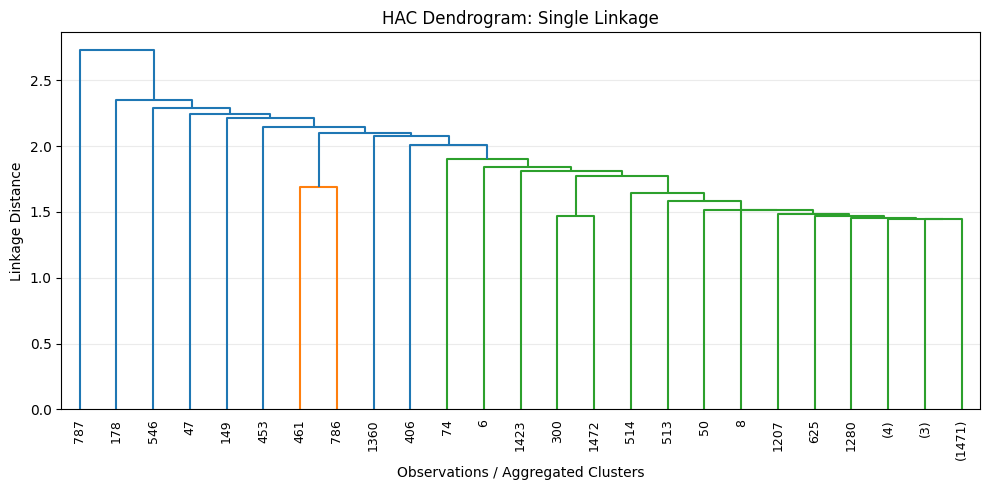

In [7]:
# Compare Ward and Single Linkage Dendrograms

from scipy.cluster.hierarchy import linkage, dendrogram

linkage_matrices = {}

for method in ["ward", "single"]:

    # Construct hierarchical clustering
    Z = linkage(
        X_hac,
        method=method,
        metric="euclidean"
    )

    linkage_matrices[method] = Z

    # Create a dendrogram
    fig, ax = plt.subplots(figsize=(10, 5))

    dendrogram(
        Z,
        truncate_mode="lastp",
        p=25,
        show_leaf_counts=True,
        leaf_rotation=90,
        leaf_font_size=9,
        ax=ax
    )

    ax.set_title(
        f"HAC Dendrogram: {method.capitalize()} Linkage"
    )

    ax.set_xlabel(
        "Observations / Aggregated Clusters"
    )

    ax.set_ylabel("Linkage Distance")

    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    plt.show()

## Comparing HAC and K-Means Cluster Profiles

Ward hierarchical clustering and K-Means are compared
using the same standardized sample of 1,500 NBA games.

Both methods use four clusters.

We investigate:
- Cluster sizes and proportions
- Sportsbook totals and point spreads
- Historical scoring trends
- Actual scoring outcomes and sportsbook errors
- Agreement between clustering assignments

The goal is to determine whether the algorithms identify
meaningfully different NBA game profiles.

Actual scores are used only for interpreting the clusters
and are not included in model fitting.

In [8]:
#  Ward HAC vs. K-Means cluster profiles

from sklearn.metrics import adjusted_rand_score

# Existing Ward K=4 labels
ward_labels = hac_labels[("ward", 4)]

# Fit K-Means K=4 on the identical sample
kmeans_4 = KMeans(
    n_clusters=4,
    n_init=10,
    random_state=42
)

kmeans_labels = kmeans_4.fit_predict(X_hac)

# Compare assignments
ari = adjusted_rand_score(
    ward_labels,
    kmeans_labels
)

print("Adjusted Rand Index (Ward vs. K-Means):")
print(round(ari, 4))

# Analyze cluster profiles
cluster_profiles = {}

for method, labels in [
    ("Ward HAC", ward_labels),
    ("K-Means", kmeans_labels)
]:

    temp = hac_sample_df.copy()
    temp["Cluster"] = labels

    # Sportsbook errors
    temp["Signed_Error"] = (
        temp["actual_total"] - temp["total"]
    )

    temp["Absolute_Error"] = (
        temp["Signed_Error"].abs()
    )

    # Exclude pushes from Over percentages
    temp["Over"] = np.where(
        temp["Signed_Error"] == 0,
        np.nan,
        (temp["Signed_Error"] > 0).astype(float)
    )

    # Cluster characteristics
    profile = (
        temp.groupby("Cluster")
        .agg(
            Games=("actual_total", "size"),
            Avg_Total=("total", "mean"),
            Avg_Spread=("spread", "mean"),
            Avg_Scoring_Edge=("scoring_edge_5", "mean"),
            Avg_Recent_Residual=("recent_residual_5", "mean"),
            Avg_Rest_Difference=("rest_difference", "mean"),
            Avg_Actual_Total=("actual_total", "mean"),
            Sportsbook_MAE=("Absolute_Error", "mean"),
            Over_Rate=("Over", "mean")
        )
    )

    profile["Share_Pct"] = (
        profile["Games"] / len(temp) * 100
    )

    profile["Over_Rate"] *= 100

    cluster_profiles[method] = profile

    print(f"\n{method}: K=4 Cluster Profiles")
    display(profile.round(2))

Adjusted Rand Index (Ward vs. K-Means):
0.3716

Ward HAC: K=4 Cluster Profiles


,Games,Avg_Total,Avg_Spread,Avg_Scoring_Edge,Avg_Recent_Residual,Avg_Rest_Difference,Avg_Actual_Total,Sportsbook_MAE,Over_Rate,Share_Pct
Cluster,,,,,,,,,,
0,432,216.97,4.16,-4.51,-1.33,-0.03,218.23,13.81,53.99,28.80
1,371,196.92,5.08,0.35,-2.99,0.54,198.81,13.78,53.53,24.73
2,375,210.17,10.16,-1.36,0.08,0.67,211.38,14.87,51.50,25.00
3,322,203.07,4.92,7.62,6.03,-0.41,202.77,14.34,46.42,21.47



K-Means: K=4 Cluster Profiles


,Games,Avg_Total,Avg_Spread,Avg_Scoring_Edge,Avg_Recent_Residual,Avg_Rest_Difference,Avg_Actual_Total,Sportsbook_MAE,Over_Rate,Share_Pct
Cluster,,,,,,,,,,
0,317,212.79,4.44,6.00,7.18,0.01,213.20,14.27,49.84,21.13
1,454,194.00,4.49,2.58,-1.38,0.17,195.56,14.07,51.33,30.27
2,336,208.01,10.81,-0.64,0.35,0.65,209.39,13.74,53.64,22.40
3,393,217.72,5.08,-6.95,-3.76,0.02,218.50,14.61,51.68,26.20



## Conclusions and Key Findings

### DBSCAN Results

DBSCAN was applied to standardized NBA game characteristics, including sportsbook totals, point spreads, recent scoring trends, and rest differences.

A k-nearest-neighbor distance plot was used to investigate epsilon values. Six parameter combinations were then evaluated using epsilon values between 1.1 and 1.7 and MinPts values of 10 and 20.

All six configurations identified one large cluster, with noise percentages ranging from 1.06% to 3.58%.

This suggests that NBA games in the sampled feature space may form one broadly connected dense region rather than several clearly separated density-based groups.

### Core, Border, and Noise Point Analysis

The configuration with epsilon = 1.1 and MinPts = 10 identified 179 noise observations.

Noise observations had larger absolute scoring edges and rest differences than core observations. For example, their average absolute rest difference was 3.34 days, compared with 0.61 days for core observations.

However, noise observations had a sportsbook MAE of 13.97 points, compared with 14.22 for core observations.

This was unexpected because unusual games might have been more difficult to predict. The results suggest that unusual pregame characteristics do not necessarily correspond to larger sportsbook prediction errors.

### Hierarchical Clustering and Linkage Methods

Hierarchical Agglomerative Clustering was evaluated using single, complete, average, and Ward linkage methods with two and four clusters.

Single linkage achieved the highest silhouette score of 0.5582 for K=2. However, it assigned 1,499 of 1,500 observations to one cluster and only one observation to the other.

This demonstrated that a high silhouette score does not always indicate a useful clustering solution.

Ward linkage produced more balanced groups. For K=4, the smallest cluster contained 322 games, and the largest contained 432 games.

The dendrograms illustrated these differences. Single linkage showed the chaining effect, while Ward linkage formed more distinct hierarchical branches.

### Ward HAC vs. K-Means

Ward HAC and K-Means were compared using the same 1,500 historical NBA games and four clusters.

The Adjusted Rand Index was 0.3716, indicating moderate agreement between their cluster assignments.

Both algorithms identified groups characterized by different sportsbook totals, point spreads, and historical scoring trends.

An unexpected finding was that a Ward cluster with strong positive historical scoring trends had an Over rate of only 46.42%. This suggests that recent scoring performance alone may not reliably predict whether games exceed sportsbook expectations.

However, these results are exploratory and do not establish a statistically significant or generalizable relationship.

### Overall Conclusion

DBSCAN and HAC provided additional insights into the structure of NBA game characteristics.

DBSCAN was useful for identifying unusual observations, but those observations did not exhibit higher sportsbook prediction errors in this sample.

HAC demonstrated that linkage methods strongly influence clustering results. Single linkage achieved high silhouette scores by isolating individual observations, while Ward linkage produced more balanced and interpretable groups.

Together with Week 10, these results demonstrate that cluster quality depends on the algorithm, distance calculations, feature scaling, and the intended application.

Although clustering revealed meaningful differences between NBA game profiles, the analysis did not demonstrate that these groups could improve predictions beyond existing sportsbook expectations.